## Metadatos

In [2]:
# Metadatos del Proyecto
from datetime import datetime
AUTOR = "Mgtr. Ronald Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ronald Osorio
Última modificación: 21/10/2026 19:28:13
----------------------------------------


## Entorno

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Montar Google Drive (te pedirá autorización en ventana emergente)
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/Colab Notebooks/Bd')
from descriptive_analysis import *

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
#--- Configuración del sistema
import warnings
warnings.filterwarnings('ignore')

#--- Configuración de constantes
from sklearn.model_selection import StratifiedKFold
SEED = 111
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
N_ITER_TUNING = 75  # <-- AUMENTADO de 30 a 75
SCORING = 'roc_auc'


## Df
Asegúrate de estar conectado a Colab

In [5]:
# Cargar directamente desde tu Drive (Asegúrate de cambiar la ruta si está en una subcarpeta)
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bd/churn_EDA.csv')
df = df.sample(frac=0.1, random_state=SEED)

## Df Final

In [6]:
df = df.drop(columns=['customer_id', 'has_cr_card', 'card_type', 'tenure', 'satisfaction_score'])
df.head()

,credit_score,geography,gender,age,balance,num_of_products,is_active_member,estimated_salary,exited,complain,point_earned
207,743,Spain,1,43,161807.18,2,1,93228.86,1,1,973
1866,735,France,1,41,179904.00,1,1,137180.95,0,0,505
9487,735,France,0,33,0.00,2,0,149474.69,0,0,999
3673,699,Spain,1,31,114493.68,1,0,138396.32,0,0,351
7178,693,Germany,1,40,120711.73,1,0,27345.18,1,1,709


## Preprocesamiento

### Separación

In [7]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Codificación de la variable objetivo (target) 
le = LabelEncoder()
y_numeric = le.fit_transform(df['exited'])
print(f"✅ Variable objetivo codificada: {np.unique(y_numeric)}")

# División del conjunto de datos (Split) 
X = df.drop(columns=["exited"])
y = y_numeric

print(f"✅ Dimensiones de X: {X.shape}")
print(f"✅ Dimensiones de y: {y.shape}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Tamaño de la división (Split size)
print('\n=== TAMAÑO DE LA DIVISIÓN ===')
print(f'Entrenamiento (Train): {X_train.shape} | Prueba (Test): {X_test.shape}')
# ✅ CORRECCIÓN: Usar df.shape en lugar de df solo
print(f'% Entrenamiento: {len(X_train)/len(X)*100:.1f}% | % Prueba: {len(X_test)/len(X)*100:.1f}%')

# Distribución de la variable objetivo (Clasificación) 
print('\n=== DISTRIBUCIÓN DEL OBJETIVO (Conteos y %) ===')
train_dist = pd.Series(y_train).value_counts(normalize=True) * 100
test_dist = pd.Series(y_test).value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Conteo Entrenamiento': pd.Series(y_train).value_counts(),
    '% Entrenamiento': train_dist.round(2),
    'Conteo Prueba': pd.Series(y_test).value_counts(),
    '% Prueba': test_dist.round(2)
})
print(dist_df)

# Verificación rápida 
print('\n=== VERIFICACIÓN ===')
diff = (train_dist - test_dist).abs().max()
if diff < 2: # Si la diferencia entre clases es menor al 2%
    print(f'✅ División balanceada: La diferencia máxima es {diff:.2f}%')
else:
    print(f'⚠️ División desbalanceada: La diferencia máxima es {diff:.2f}%. Considere usar stratify=y')

✅ Variable objetivo codificada: [0 1]
✅ Dimensiones de X: (1000, 10)
✅ Dimensiones de y: (1000,)

=== TAMAÑO DE LA DIVISIÓN ===
Entrenamiento (Train): (800, 10) | Prueba (Test): (200, 10)
% Entrenamiento: 80.0% | % Prueba: 20.0%

=== DISTRIBUCIÓN DEL OBJETIVO (Conteos y %) ===
   Conteo Entrenamiento  % Entrenamiento  Conteo Prueba  % Prueba
0                   622            77.75            156      78.0
1                   178            22.25             44      22.0

=== VERIFICACIÓN ===
✅ División balanceada: La diferencia máxima es 0.25%


### Modificaciones de X_train

#### Duplicados

In [8]:
check_duplicates(X_train, subset = None)


DUPLICATES ANALYSIS
Rows with duplicated None: 0 (0.00%)
✓ No duplicates found


#### Numéricos (Nulos, Valores Atípicos, Escalado)

No aplica usar valores atípicos en la variable 'y' porque solo tiene 2 clases/valores al ser una clasificación binaria.

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin

# Transformador personalizado para el manejo de valores atípicos mediante IQR
class OutlierClipper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_arr = np.asarray(X)

        Q1 = np.nanpercentile(X_arr, 25, axis=0)
        Q3 = np.nanpercentile(X_arr, 75, axis=0)
        IQR = Q3 - Q1
        self.lower_ = Q1 - self.factor * IQR
        self.upper_ = Q3 + self.factor * IQR
        return self

    def transform(self, X):
        # Recorta los valores fuera de los límites calculados
        return np.clip(np.asarray(X), self.lower_, self.upper_)

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

# NUMÉRICO - LINEAL
num_pipe_linear = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clipper', OutlierClipper(factor=1.5)),
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)) # <-- transforma escala y distribución
])

# NUMÉRICO - ÁRBOLES
num_pipe_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

#### Categóricos (Codificación)

In [11]:
from sklearn.preprocessing import OneHotEncoder

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # codificar
])

#### Binario (Codificación)

In [12]:
from sklearn.preprocessing import OrdinalEncoder

bi_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder())
])

#### Conversión a Columnas Categóricas
No requerido

#### Ingeniería de Características

Simple <br>
Ninguna

Complejo <br>
Ninguna

#### Columnas

In [13]:
num_cols = ['credit_score', 'age', 'balance', 'num_of_products', 'estimated_salary', 'point_earned' ]
cat_cols = ['geography']
bi_cols = ['gender', 'is_active_member', 'complain' ]

#### Todas las Transformaciones

In [14]:
from sklearn.compose import ColumnTransformer

preprocessor_linear = ColumnTransformer([ # <-- No se usa pipeline porque no tiene ingeniería de características. Si la tuviera, se usaría solo ColumnTransformer
    ('num', num_pipe_linear, num_cols),
    ('cat', cat_pipe, cat_cols),
    ('bin', bi_pipe, bi_cols)
], remainder='drop')

preprocessor_tree = ColumnTransformer([ # <-- No se usa pipeline porque no tiene ingeniería de características. Si la tuviera, se usaría solo ColumnTransformer
    ('num', num_pipe_tree, num_cols),
    ('cat', cat_pipe, cat_cols),
    ('bin', bi_pipe, bi_cols)
], remainder='drop')

# Algoritmos

## Pipeline Integrado para Benchmarking, Optimización y Validación de Robustez

### Configuración del Entorno y Modelos

#### Definición del Espacio de Búsqueda (PARAM_DISTS)

In [15]:
from scipy.stats import loguniform, randint, uniform

PARAM_GRIDS = {

    # === 1. LÍNEAS BASE (BASELINES) ===
    'Naive Bayes': {
        'model__var_smoothing': loguniform(1e-10, 1e-3)
    },

    'Logistic Regression': [
        {   # Combinación 1: lbfgs solo admite l2
            'model__solver': ['lbfgs'],
            'model__penalty': ['l2'],
            'model__C': loguniform(0.001, 1000),
            'model__max_iter': [1000, 2000],
            'model__class_weight': ['balanced', None]
        },
        {   # Combinación 2: liblinear y saga admiten l1 y l2
            'model__solver': ['liblinear', 'saga'],
            'model__penalty': ['l1', 'l2'],
            'model__C': loguniform(0.001, 1000),
            'model__max_iter': [1000, 2000],
            'model__class_weight': ['balanced', None]
        }
    ],

    # === 2. DISTANCIA Y KERNELS ===
    'SVC': {
        'model__C': loguniform(0.01, 1000),
        'model__gamma': loguniform(0.0001, 10),
        'model__kernel': ['rbf','linear'],
        'model__probability': [True],
        # 'model__decision_function_shape': ['ovo', 'ovr'], # <-- Solo se usa si es multiclase
    },

    'KNN': {
        'model__n_neighbors': randint(2, 20),
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['euclidean', 'manhattan', 'minkowski'],
        'model__p': [1, 2, 3]
    },

    # === 3. ÁRBOLES Y BAGGING ===
    'Decision Tree': {
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': randint(2, 15),
        'model__min_samples_split': randint(2, 15),
        'model__min_samples_leaf': randint(1, 8),
        'model__splitter': ['best', 'random'],
        'model__max_features': ['sqrt', 'log2', None]
    },

    'Random Forest': {
        'model__n_estimators': randint(100, 500),
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': randint(3, 20),
        'model__min_samples_split': randint(2, 15),
        'model__min_samples_leaf': randint(1, 8),
        'model__max_features': ['sqrt', 'log2', None],
        'model__bootstrap': [True],
        'model__class_weight': ['balanced', 'balanced_subsample', None],
        'model__max_samples': [None, 0.5, 0.7, 0.9]
    },

    'Extra Trees': {
        'model__n_estimators': randint(100, 500),
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': randint(3, 25),
        'model__min_samples_split': randint(2, 15),
        'model__min_samples_leaf': randint(1, 8),
        'model__max_features': ['sqrt', 'log2', None],
        'model__bootstrap': [True, False],
        'model__class_weight': ['balanced', 'balanced_subsample', None]
    },

    # === 4. BOOSTING ===
    'Gradient Boosting': {
        'model__n_estimators': randint(100, 300),
        'model__max_depth': randint(1, 8),
        'model__learning_rate': loguniform(0.001, 0.5),
        'model__subsample': uniform(0.5, 0.5),
        'model__min_samples_split': randint(2, 10),
        'model__min_samples_leaf': randint(1, 5),
        'model__max_features': ['sqrt', 'log2', None]
    },

    'XGBoost': {
        'model__n_estimators': randint(100, 400),
        'model__max_depth': randint(2, 10),
        'model__learning_rate': loguniform(0.001, 0.3),
        'model__subsample': uniform(0.5, 0.5),  # <-- CRÍTICO
        'model__colsample_bytree': uniform(0.5, 0.5),
        'model__reg_alpha': loguniform(0.001, 10),
        'model__reg_lambda': loguniform(0.001, 10),
        'model__min_child_weight': randint(1, 5),
        'model__objective': ['binary:logistic'], # <-- Multiclass si tiene más de 2 opciones
        'model__eval_metric': ['logloss']
    },

    'LightGBM': {
        'model__objective': ['binary'], # <-- Multiclass si tiene más de 2 opciones
        'model__num_leaves': randint(10, 50),
        'model__max_depth': randint(3, 12),
        'model__n_estimators': randint(100, 300),
        'model__learning_rate': loguniform(0.001, 0.2),
        'model__feature_fraction': uniform(0.5, 0.5),
        'model__bagging_fraction': uniform(0.5, 0.5),
        'model__bagging_freq': [1, 5, 10],
        'model__min_child_samples': randint(5, 30),
        'model__reg_alpha': loguniform(0.001, 10),
        'model__reg_lambda': loguniform(0.001, 10)
    },

    'HistGradientBoosting': {
        'model__max_iter': randint(100, 400),
        'model__max_depth': randint(2, 10),
        'model__learning_rate': loguniform(0.001, 0.3),
        'model__l2_regularization': loguniform(0.01, 100),
        'model__max_leaf_nodes': randint(20, 150),
        'model__max_bins': [255, 128, 64]
    },

    # === 5. REDES NEURONALES ===
    'Neural Network': {
        'model__hidden_layer_sizes': [
            (32,), (64,), (128,),
            (64, 32), (128, 64), (256, 128),
            (128, 64, 32), (256, 128, 64)
        ],
        'model__activation': ['tanh', 'relu', 'logistic'],
        'model__solver': ['adam', 'sgd'],  # <-- IMPORTANTE
        'model__alpha': loguniform(1e-5, 1e-1),
        'model__learning_rate': ['constant', 'adaptive'],
        'model__learning_rate_init': loguniform(1e-4, 0.1),
        'model__batch_size': [16, 32, 64],
        'model__max_iter': [1000, 2000],
        'model__early_stopping': [True]
    }
}

#### Construcción de Pipelines (Modelos)

In [16]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
import lightgbm as lgb

MODELS = {
    # MODELOS LINEALES Y DISTANCIAS (Usan preprocessor_linear con escalado/clipper)
    'Naive Bayes': Pipeline([
        ('prep', preprocessor_linear),
        ('model', GaussianNB())
    ]),

    'Logistic Regression': Pipeline([
        ('prep', preprocessor_linear),
        ('model', LogisticRegression(random_state=SEED, max_iter=1000))
    ]),

    'SVC': Pipeline([
        ('prep', preprocessor_linear),
        ('model', SVC(probability=True, random_state=SEED))
    ]),

    'KNN': Pipeline([
        ('prep', preprocessor_linear),
        ('model', KNeighborsClassifier())
    ]),

    'Neural Network': Pipeline([
        ('prep', preprocessor_linear),
        ('model', MLPClassifier(random_state=SEED, max_iter=1000, early_stopping=True))
    ]),

    # MODELOS DE ÁRBOLES Y BOOSTING (Usan preprocessor_tree sin clipper ni PowerTransformer)
    'Decision Tree': Pipeline([
        ('prep', preprocessor_tree),
        ('model', DecisionTreeClassifier(random_state=SEED))
    ]),

    'Random Forest': Pipeline([
        ('prep', preprocessor_tree),
        ('model', RandomForestClassifier(random_state=SEED, n_jobs=-1))
    ]),

    'Extra Trees': Pipeline([
        ('prep', preprocessor_tree),
        ('model', ExtraTreesClassifier(random_state=SEED, n_jobs=-1))
    ]),

    'Gradient Boosting': Pipeline([
        ('prep', preprocessor_tree),
        ('model', GradientBoostingClassifier(random_state=SEED))
    ]),

    'XGBoost': Pipeline([
        ('prep', preprocessor_tree),
        ('model', XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='logloss', verbosity=0))
    ]),

    'LightGBM': Pipeline([
        ('prep', preprocessor_tree),
        ('model', lgb.LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1))
    ]),

    'HistGradientBoosting': Pipeline([
        ('prep', preprocessor_tree),
        ('model', HistGradientBoostingClassifier(random_state=SEED))
    ]),
}

### Entrenamiento Base

In [17]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score

benchmark_rows = []

for name, model in MODELS.items():
    # CV inicial
    cv_AUC = cross_val_score(model, X_train, y_train, cv=CV, scoring=SCORING).mean()
    model.fit(X_train, y_train)

    # Evaluación base
    test_AUC = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

    benchmark_rows.append({
        'Model': name,
        'Test AUC (default)': round(test_AUC, 4),
        'CV AUC (default)': round(cv_AUC, 4)
    })

benchmark_df = pd.DataFrame(benchmark_rows).sort_values('Test AUC (default)', ascending=False)
display(benchmark_df.style.background_gradient(cmap='RdYlGn'))

,Model,Test AUC (default),CV AUC (default)
0,Naive Bayes,1.000000,1.000000
1,Logistic Regression,1.000000,1.000000
2,SVC,1.000000,1.000000
4,Neural Network,1.000000,0.854300
8,Gradient Boosting,1.000000,1.000000
5,Decision Tree,1.000000,1.000000
6,Random Forest,1.000000,1.000000
7,Extra Trees,1.000000,1.000000
10,LightGBM,1.000000,1.000000
9,XGBoost,1.000000,1.000000


### Optimización de Hiperparámetros (Ajuste)

#### Proceso de Búsqueda (Ajuste)

In [18]:

# Función de ejecución del ajuste (tuning)
def tune_model(name, model, dist, X_train, y_train):
    if not dist:
        model.fit(X_train, y_train)
        best_est = model
        best_params = {}
        best_cv_AUC = cross_val_score(model, X_train, y_train, cv=CV, scoring=SCORING).mean()
    else:
        rs = RandomizedSearchCV(
            model, dist,
            n_iter=N_ITER_TUNING,
            cv=CV,
            scoring=SCORING,
            n_jobs=-1,
            random_state=SEED,
            refit=True,
            error_score='raise',
            verbose=0
        )
        rs.fit(X_train, y_train)
        best_est = rs.best_estimator_
        best_params = rs.best_params_
        best_cv_AUC = rs.best_score_

    return best_est, best_params, best_cv_AUC

#### Entrenamiento y Evaluación Detallada

In [19]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

# Bucle de entrenamiento y evaluación NUEVO
print("\n" + "="*70)
print("INICIANDO AJUSTE (TUNING) DE MODELOS (N_ITER=75, CV=5)")
print("="*70)

BEST_MODELS = {}
BEST_PARAMS = {}
tuning_results = []
BEST_MODELS_RAW = {}


for name, model in MODELS.items():
    print(f"Ajustando {name}...", end=" ", flush=True)

    dist = PARAM_GRIDS.get(name, {})
    best_est, best_params, best_cv_AUC = tune_model(name, model, dist, X_train, y_train)

    final_est = best_est   # por defecto, sin calibrar
    if name not in ['Logistic Regression', 'Neural Network', 'SVC']:
        try:
            final_est = CalibratedClassifierCV(best_est, method='sigmoid', cv=5, n_jobs=-1)
            final_est.fit(X_train, y_train)
        except Exception as e:
            print(f" [Aviso: Falló la calibración de {name}: {e}] ", end="")
            final_est = best_est

    BEST_MODELS[name] = final_est
    BEST_MODELS_RAW[name] = best_est
    BEST_PARAMS[name] = best_params

    y_pred_train = final_est.predict(X_train)
    y_pred_test = final_est.predict(X_test)

    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    test_f1 = f1_score(y_test, y_pred_test, average='binary')
    test_precision = precision_score(y_test, y_pred_test, average='binary', zero_division=0)
    test_recall = recall_score(y_test, y_pred_test, average='binary', zero_division=0)

    try:
        y_proba_test = final_est.predict_proba(X_test)
        y_proba_train = final_est.predict_proba(X_train)
        auc_test = roc_auc_score(y_test, y_proba_test[:, 1])
        auc_train = roc_auc_score(y_train, y_proba_train[:, 1])
        auc_gap = round(auc_train - auc_test, 4)
    except Exception as e:
        print(f" [Error AUC {name}: {e}] ", end="")
        auc_test = np.nan
        auc_train = np.nan
        auc_gap = np.nan

    cm = confusion_matrix(y_test, y_pred_test)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)

    tuning_results.append({
        'Model': name,
        'Test Acc': round(test_acc, 4),
        'CV AUC': round(best_cv_AUC, 4),
        'Train Acc': round(train_acc, 4),
        'AUC Train': round(auc_train, 4),
        'AUC Test': round(auc_test, 4),
        'AUC Gap': round(auc_train - auc_test, 4),
        'Test F1': round(test_f1, 4),
        'Precision': round(test_precision, 4),
        'Recall': round(test_recall, 4),
        'Specificity': round(specificity, 4),
        'Gap (Train-Test)': round(train_acc - test_acc, 4),
        'Test AUC (default)': benchmark_df.loc[benchmark_df['Model'] == name, 'Test AUC (default)'].values[0],
        'Δ AUC': round(auc_test - benchmark_df.loc[benchmark_df['Model'] == name, 'Test AUC (default)'].values[0], 4)
    })

    print(f"✅ | Acc={test_acc:.4f} | F1={test_f1:.4f}")

# Visualización del reporte de resumen
tuning_df = pd.DataFrame(tuning_results).sort_values('AUC Test', ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print(" RESULTADOS DEL TUNING")
print("="*70)
display(tuning_df.drop(columns='Test AUC (default)').style.background_gradient(cmap='RdYlGn', subset=['AUC Test', 'Test F1']))

# Verificación rápida
print('\n=== VERIFICACIÓN ===')
print('AUC Test: mayor = mejor | CV AUC: mayor = mejor')
print('Brecha (Train-Test): ~0 = bueno | >0 = sobreajuste (overfitting) | <0 = subajuste (underfitting)')
print('F1-Score: mayor = mejor | Precisión/Recall: el balance importa')
print('CRITERIO FINAL: 1) CV AUC ↑ 2) F1 ↑ 3) Brecha (Gap) ≈ 0')


INICIANDO AJUSTE (TUNING) DE MODELOS (N_ITER=75, CV=5)
Ajustando Naive Bayes... ✅ | Acc=1.0000 | F1=1.0000
Ajustando Logistic Regression... ✅ | Acc=1.0000 | F1=1.0000
Ajustando SVC... ✅ | Acc=1.0000 | F1=1.0000
Ajustando KNN... ✅ | Acc=0.9700 | F1=0.9286
Ajustando Neural Network... ✅ | Acc=1.0000 | F1=1.0000
Ajustando Decision Tree... ✅ | Acc=1.0000 | F1=1.0000
Ajustando Random Forest... ✅ | Acc=1.0000 | F1=1.0000
Ajustando Extra Trees... ✅ | Acc=1.0000 | F1=1.0000
Ajustando Gradient Boosting... ✅ | Acc=1.0000 | F1=1.0000
Ajustando XGBoost... ✅ | Acc=1.0000 | F1=1.0000
Ajustando LightGBM... ✅ | Acc=1.0000 | F1=1.0000
Ajustando HistGradientBoosting... ✅ | Acc=1.0000 | F1=1.0000

 RESULTADOS DEL TUNING


,Model,Test Acc,CV AUC,Train Acc,AUC Train,AUC Test,AUC Gap,Test F1,Precision,Recall,Specificity,Gap (Train-Test),Δ AUC
0,Naive Bayes,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
1,Logistic Regression,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
2,SVC,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
3,Neural Network,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
4,Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
5,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
6,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
7,Extra Trees,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
8,LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
9,XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000



=== VERIFICACIÓN ===
AUC Test: mayor = mejor | CV AUC: mayor = mejor
Brecha (Train-Test): ~0 = bueno | >0 = sobreajuste (overfitting) | <0 = subajuste (underfitting)
F1-Score: mayor = mejor | Precisión/Recall: el balance importa
CRITERIO FINAL: 1) CV AUC ↑ 2) F1 ↑ 3) Brecha (Gap) ≈ 0


Calibración


📊 GENERANDO DIAGRAMAS DE FIABILIDAD (CALIBRACIÓN) PARA TODOS LOS MODELOS


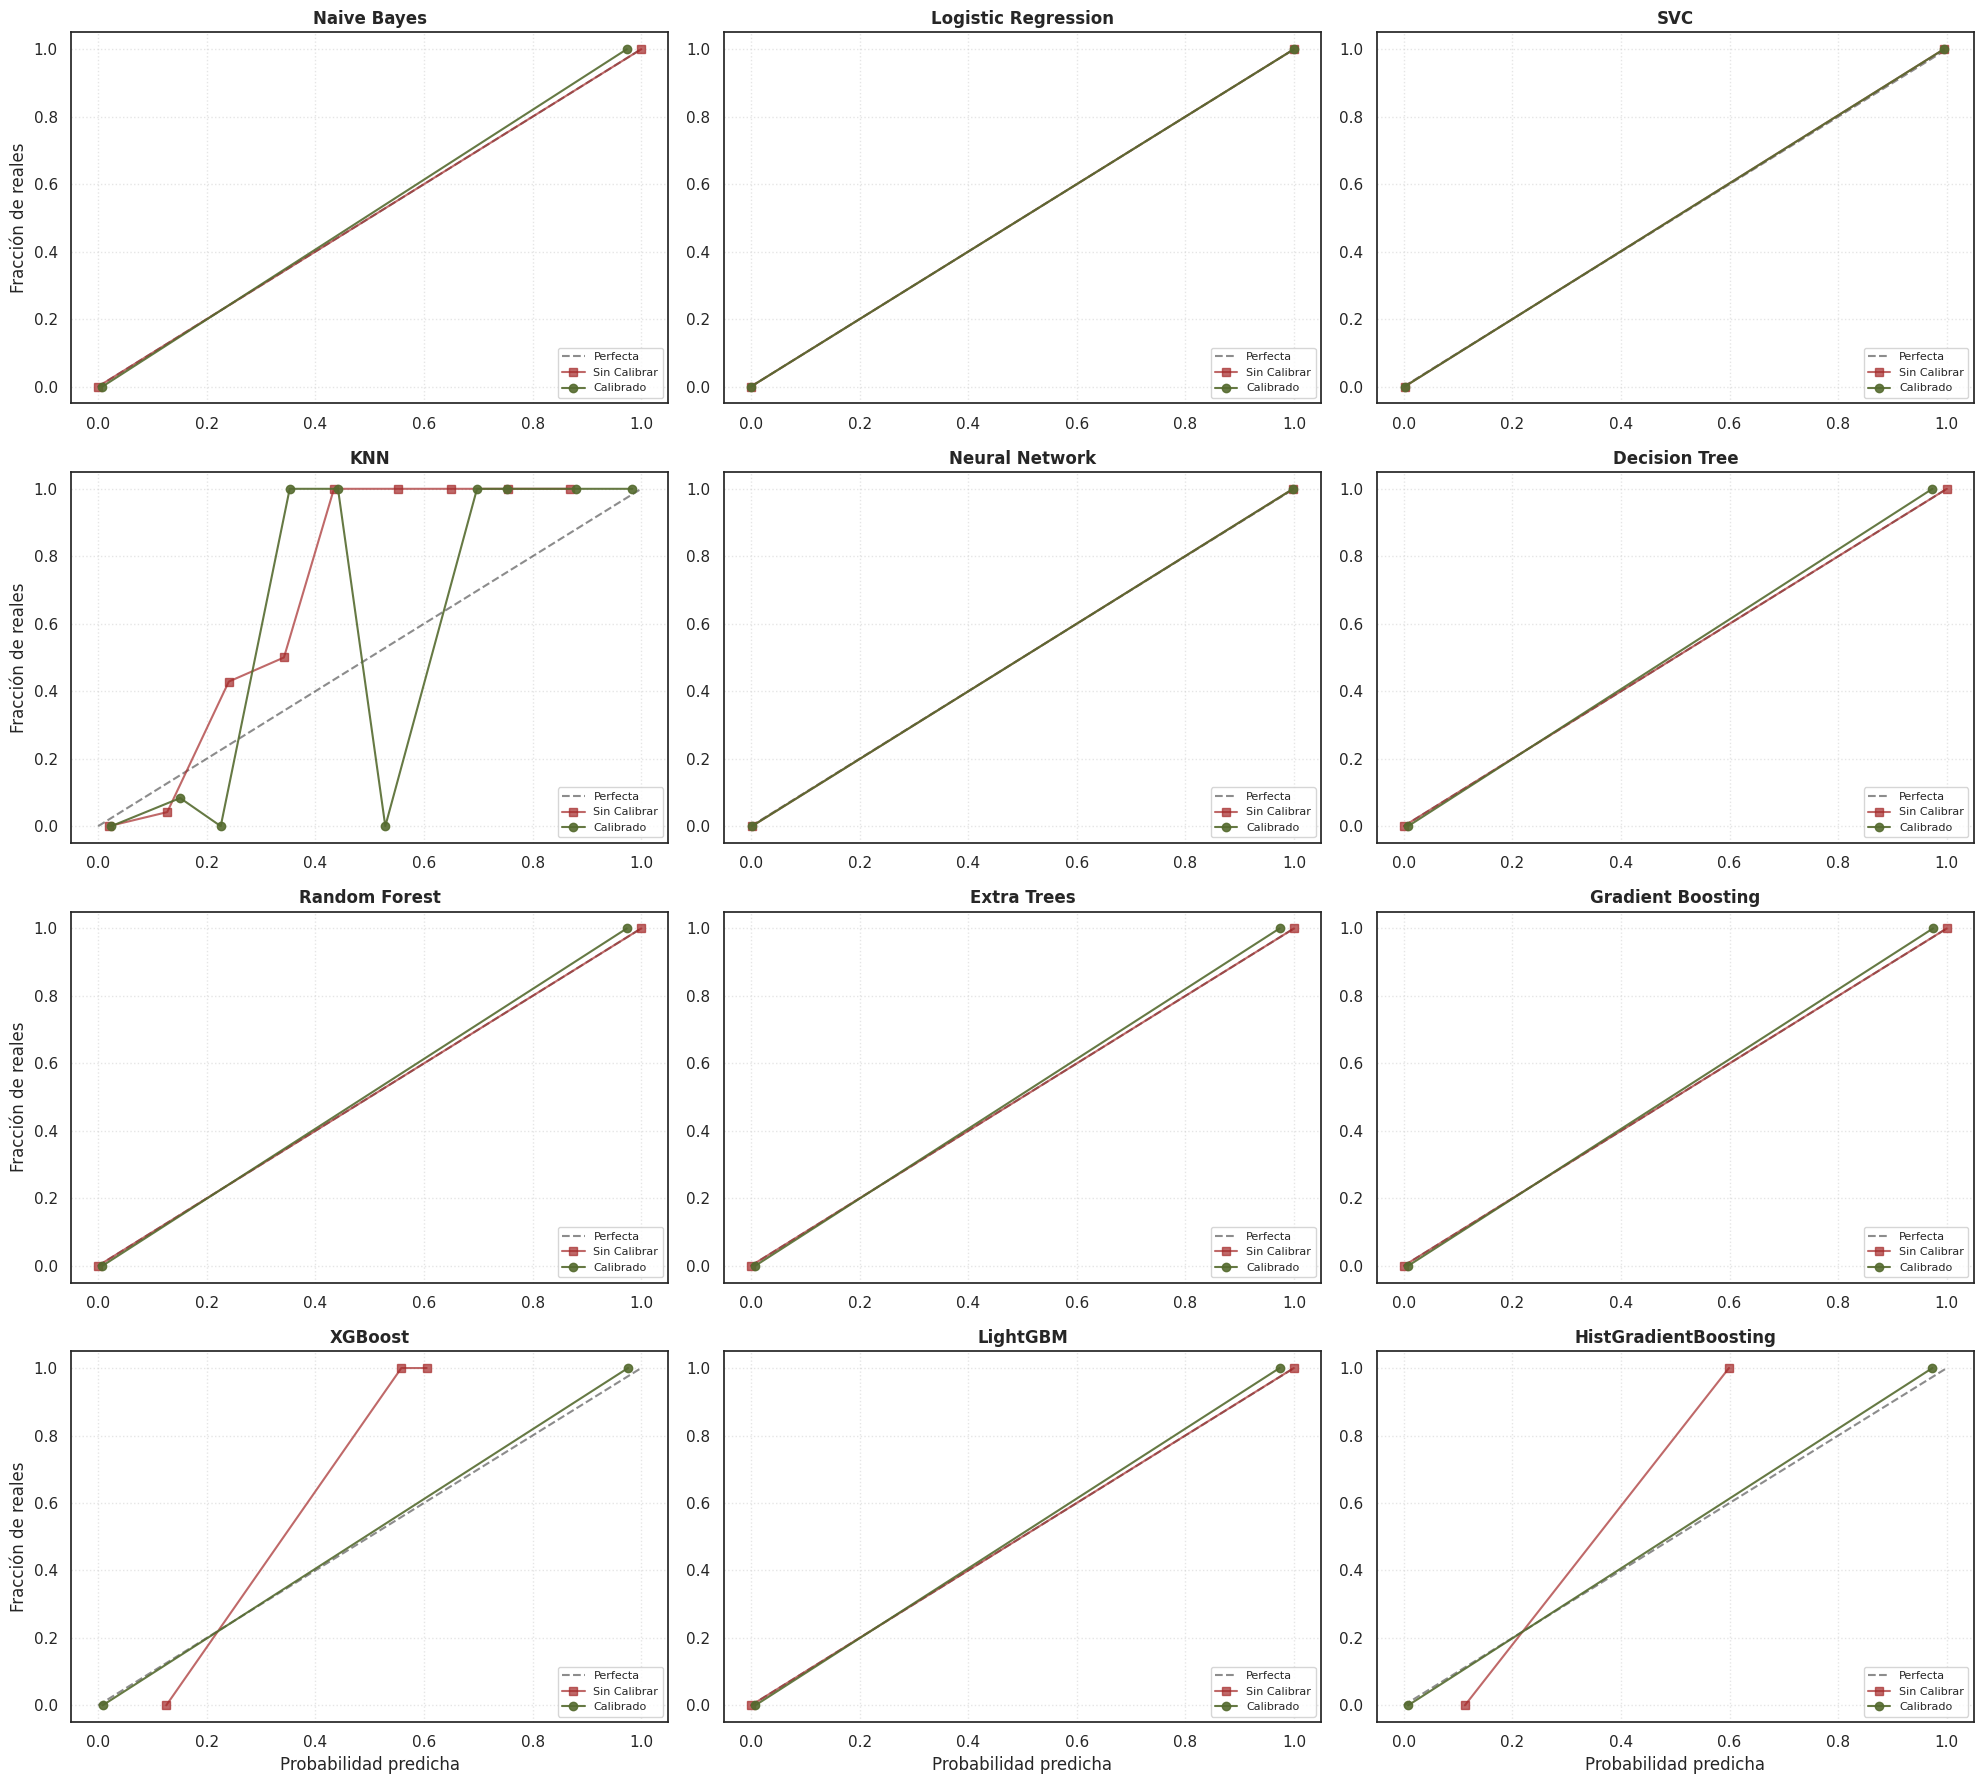

In [20]:
from sklearn.calibration import calibration_curve
from sklearn.base import clone

# Configuración de la grilla (4 columnas)
models_to_plot = list(BEST_MODELS.keys())
n_models = len(models_to_plot)
cols = 3
rows = (n_models // cols) + (1 if n_models % cols > 0 else 0)

fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))
axes = axes.flatten()

clase_a_evaluar = 1  # Evaluamos la primera clase (clase 1)
y_test_binary = (y_test == clase_a_evaluar).astype(int)

print("\n" + "="*70)
print("📊 GENERANDO DIAGRAMAS DE FIABILIDAD (CALIBRACIÓN) PARA TODOS LOS MODELOS")
print("="*70)

for idx, name in enumerate(models_to_plot):
    ax = axes[idx]

    # Modelo Calibrado (el que guardaste en BEST_MODELS)
    calibrated_model_obj = BEST_MODELS[name]

    # Modelo Sin Calibrar (Clonamos el original desde MODELS y lo entrenamos rápido)
    base_model_uncalibrated = clone(BEST_MODELS_RAW[name])
    base_model_uncalibrated.fit(X_train, y_train)

    # Obtener probabilidades de la clase evaluada
    try:
        prob_uncal = base_model_uncalibrated.predict_proba(X_test)[:, clase_a_evaluar]
        prob_cal = calibrated_model_obj.predict_proba(X_test)[:, clase_a_evaluar]

        # Calcular curvas de calibración
        fraction_of_positives_uncal, mean_predicted_value_uncal = calibration_curve(y_test_binary, prob_uncal, n_bins=10)
        fraction_of_positives_cal, mean_predicted_value_cal = calibration_curve(y_test_binary, prob_cal, n_bins=10)

        # Graficar líneas
        ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfecta")
        ax.plot(mean_predicted_value_uncal, fraction_of_positives_uncal, "s-", color="#A52A2A", alpha=0.7, label="Sin Calibrar")
        ax.plot(mean_predicted_value_cal, fraction_of_positives_cal, "o-", color="#556B2F", alpha=0.9, label="Calibrado")

    except Exception as e:
        # Por si algún modelo base específico da problemas con predict_proba antes de calibrar
        ax.text(0.5, 0.5, f"No disponible para\n{name}", va='center', ha='center', fontsize=10, style='italic')

    # Estilo de cada sub-gráfico
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])
    if idx % cols == 0:
        ax.set_ylabel("Fracción de reales")
    if idx >= (rows - 1) * cols:
        ax.set_xlabel("Probabilidad predicha")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.5)

# Eliminar ejes vacíos si sobran espacios en la grilla
for idx in range(n_models, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

#### Resumen de Mejores Parámetros

In [21]:
print('=== MEJORES PARÁMETROS ENCONTRADOS ===\n')
for name, params in BEST_PARAMS.items():
    print(f"▸ {name}")
    if params:
        for key, value in params.items():
            print(f"   {key}: {value}")
    else:
        print(f"   (Sin parámetros para tunear)")
    print()

=== MEJORES PARÁMETROS ENCONTRADOS ===

▸ Naive Bayes
   model__var_smoothing: 1.928373831294379e-06

▸ Logistic Regression
   model__C: 41.26433353280405
   model__class_weight: balanced
   model__max_iter: 1000
   model__penalty: l1
   model__solver: saga

▸ SVC
   model__C: 11.50405311175064
   model__gamma: 0.0007004042484561544
   model__kernel: rbf
   model__probability: True

▸ KNN
   model__metric: minkowski
   model__n_neighbors: 19
   model__p: 1
   model__weights: uniform

▸ Neural Network
   model__activation: tanh
   model__alpha: 3.0411029949314832e-05
   model__batch_size: 16
   model__early_stopping: True
   model__hidden_layer_sizes: (128, 64, 32)
   model__learning_rate: adaptive
   model__learning_rate_init: 0.02031362437695551
   model__max_iter: 1000
   model__solver: adam

▸ Decision Tree
   model__criterion: gini
   model__max_depth: 14
   model__max_features: sqrt
   model__min_samples_leaf: 5
   model__min_samples_split: 8
   model__splitter: random

▸ Random F

### Análisis de Resultados e Impacto

#### Comparación antes vs. después del ajuste: Sobreajuste vs. Subajuste (Overfitting vs. Underfitting)

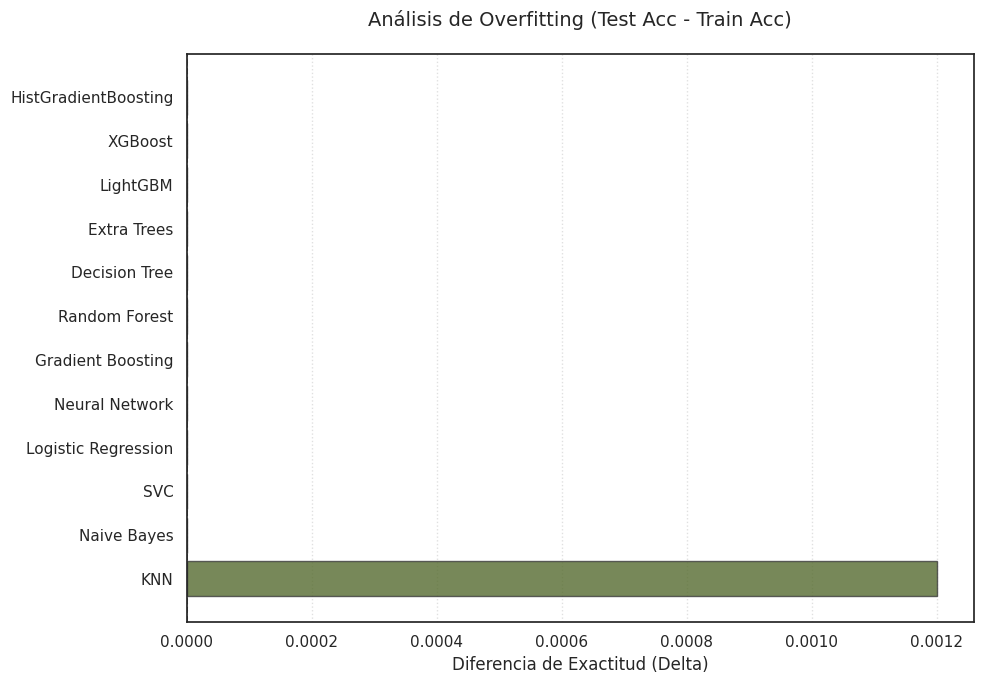

In [22]:
fig, ax = plt.subplots(figsize=(10, 7))
tuning_df['Delta_Overfitting'] = tuning_df['Test Acc'] - tuning_df['Train Acc']
df_sorted = tuning_df.sort_values('Delta_Overfitting', ascending=False)
colors = ['#556B2F' if v >= 0 else '#A52A2A' for v in df_sorted['Delta_Overfitting']]
ax.barh(df_sorted['Model'], df_sorted['Delta_Overfitting'], color=colors, edgecolor='#3D3D3D', alpha=0.8)

ax.axvline(0, color='#3D3D3D', lw=1.2, linestyle='--')
ax.set_title('Análisis de Overfitting (Test Acc - Train Acc)', fontsize=14, pad=20)
ax.set_xlabel('Diferencia de Exactitud (Delta)', fontsize=12)
ax.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

#### Ganancia Neta por Optimización de Hiperparámetros

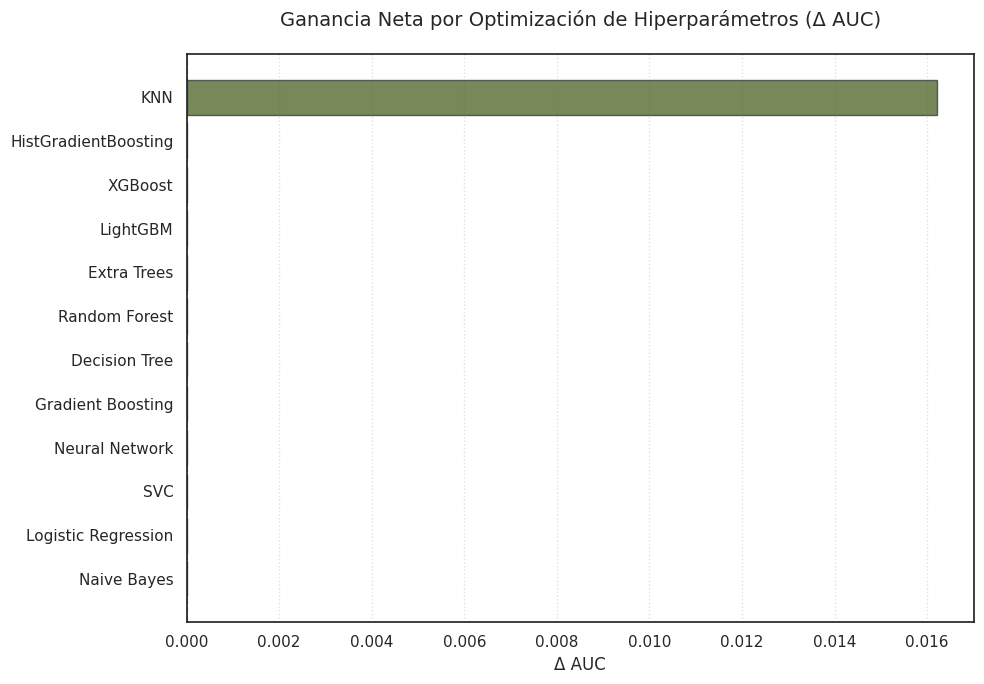

In [23]:
tuning_impact = tuning_df.sort_values('Δ AUC', ascending=True)

# Usar el mismo figsize que el de Overfitting (10, 7)
plt.figure(figsize=(10, 7))

colors = ['#556B2F' if v >= 0 else '#A52A2A' for v in tuning_impact['Δ AUC']]

# El truco: height=0.8 para barras bien anchas y edgecolor para el diseño
plt.barh(tuning_impact['Model'], tuning_impact['Δ AUC'],
         color=colors,
         edgecolor='#3D3D3D',
         height=0.8,
         alpha=0.8)

plt.axvline(0, color='#3D3D3D', lw=1.2, linestyle='--')
plt.title('Ganancia Neta por Optimización de Hiperparámetros (Δ AUC)', fontsize=14, pad=20)
plt.xlabel('Δ AUC', fontsize=12)

# Grid opcional para que sea idéntico al anterior
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Pruebas de Robustez (Validación Final)

#### Validación Cruzada K-Fold: Estabilidad Interna por División del Conjunto y Uso de Hiperparámetros Óptimos

In [24]:
# Estabilidad K-Fold (Consistencia interna) ANTIGUO
cv_stability = []
for name, model in BEST_MODELS.items():
    scores = cross_val_score(model, X_train, y_train, cv=CV, scoring=SCORING)
    cv_stability.append({
        'Model': name,
        'CV AUC Mean': round(scores.mean(), 4),
        'CV AUC Std': round(scores.std(), 4), # ¡Esto es clave!
    })

cv_stable_df = pd.DataFrame(cv_stability).sort_values('CV AUC Mean', ascending=False)
display(cv_stable_df.style.background_gradient(cmap='RdYlGn', subset=['CV AUC Std']))

,Model,CV AUC Mean,CV AUC Std
0,Naive Bayes,1.000000,0.000000
1,Logistic Regression,1.000000,0.000000
2,SVC,1.000000,0.000000
4,Neural Network,1.000000,0.000000
8,Gradient Boosting,1.000000,0.000000
5,Decision Tree,1.000000,0.000000
6,Random Forest,1.000000,0.000000
7,Extra Trees,1.000000,0.000000
10,LightGBM,1.000000,0.000000
9,XGBoost,1.000000,0.000000


#### Prueba de Estabilidad con Múltiples Semillas: Estabilidad Externa con Diferentes Semillas y Uso de Hiperparámetros Óptimos

In [25]:
SEEDS = [7, 19, 58, 73, 101]   # 5 semillas para que no tarde demasiado
stability = []

for name, model in BEST_MODELS.items():
    aucs = []
    for s in SEEDS:
        cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
        try:
            scores = cross_val_score(clone(model), X_train, y_train, cv=cv_s, scoring=SCORING)
            aucs.append(scores.mean())
        except Exception as e:
            print(f"{name} (semilla {s}): {e}")
            continue

    if aucs:
        stability.append({
            'Model': name,
            'AUC Mean': round(np.mean(aucs), 4),
            'AUC Std': round(np.std(aucs), 4),
            'Range': round(max(aucs) - min(aucs), 4),
        })

stability_df = pd.DataFrame(stability).sort_values('AUC Mean', ascending=False)
print("\n=== ESTABILIDAD CON MÚLTIPLES SEMILLAS ===")
display(stability_df.style.background_gradient(cmap='RdYlGn', subset=['AUC Mean', 'AUC Std', 'Range']))


=== ESTABILIDAD CON MÚLTIPLES SEMILLAS ===


,Model,AUC Mean,AUC Std,Range
0,Naive Bayes,1.000000,0.000000,0.000000
1,Logistic Regression,1.000000,0.000000,0.000000
2,SVC,1.000000,0.000000,0.000000
4,Neural Network,1.000000,0.000000,0.000000
8,Gradient Boosting,1.000000,0.000000,0.000000
5,Decision Tree,1.000000,0.000000,0.000000
6,Random Forest,1.000000,0.000000,0.000000
7,Extra Trees,1.000000,0.000000,0.000000
10,LightGBM,1.000000,0.000000,0.000000
9,XGBoost,1.000000,0.000000,0.000000


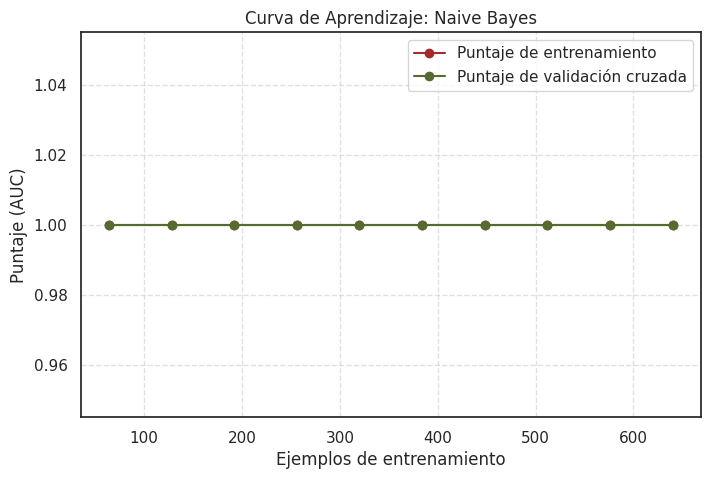

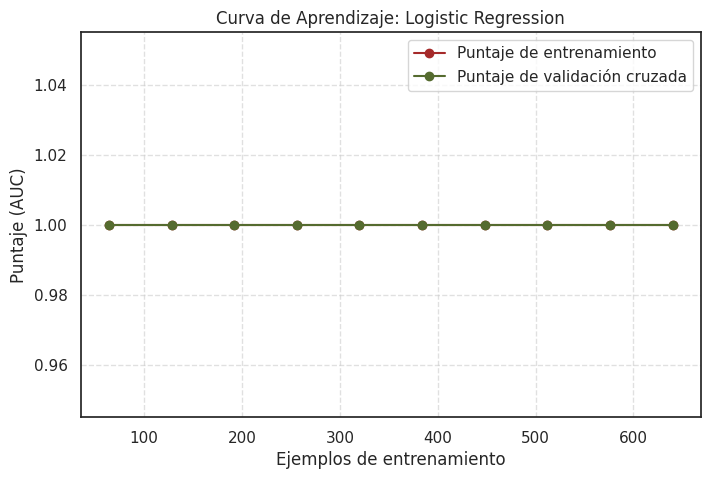

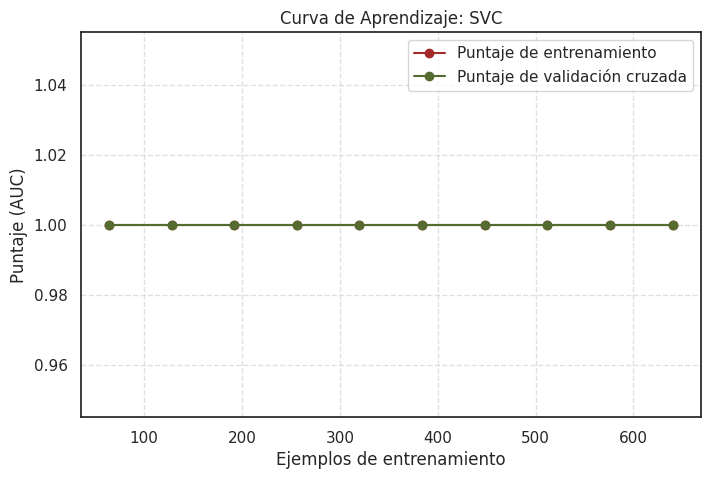

In [26]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(model, name, X, y):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y, cv=5, n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), scoring=SCORING
    )

    # Calcular promedios y desviaciones
    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, 'o-', color="#A52A2A", label="Puntaje de entrenamiento")
    plt.plot(train_sizes, test_mean, 'o-', color="#556B2F", label="Puntaje de validación cruzada")

    plt.title(f"Curva de Aprendizaje: {name}")
    plt.xlabel("Ejemplos de entrenamiento")
    plt.ylabel("Puntaje (AUC)")
    plt.legend(loc="best")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

for name, model in [(n, BEST_MODELS[n]) for n in tuning_df.sort_values('CV AUC', ascending=False)['Model'].head(3)]:  # Top 3
    # Obtener el modelo del ranking ordenado

    plot_learning_curve(BEST_MODELS[name], name, X_train, y_train)

## Evaluación Global 

### Matriz de Confusión con %


📈 GENERANDO MATRICES DE CONFUSIÓN CON %


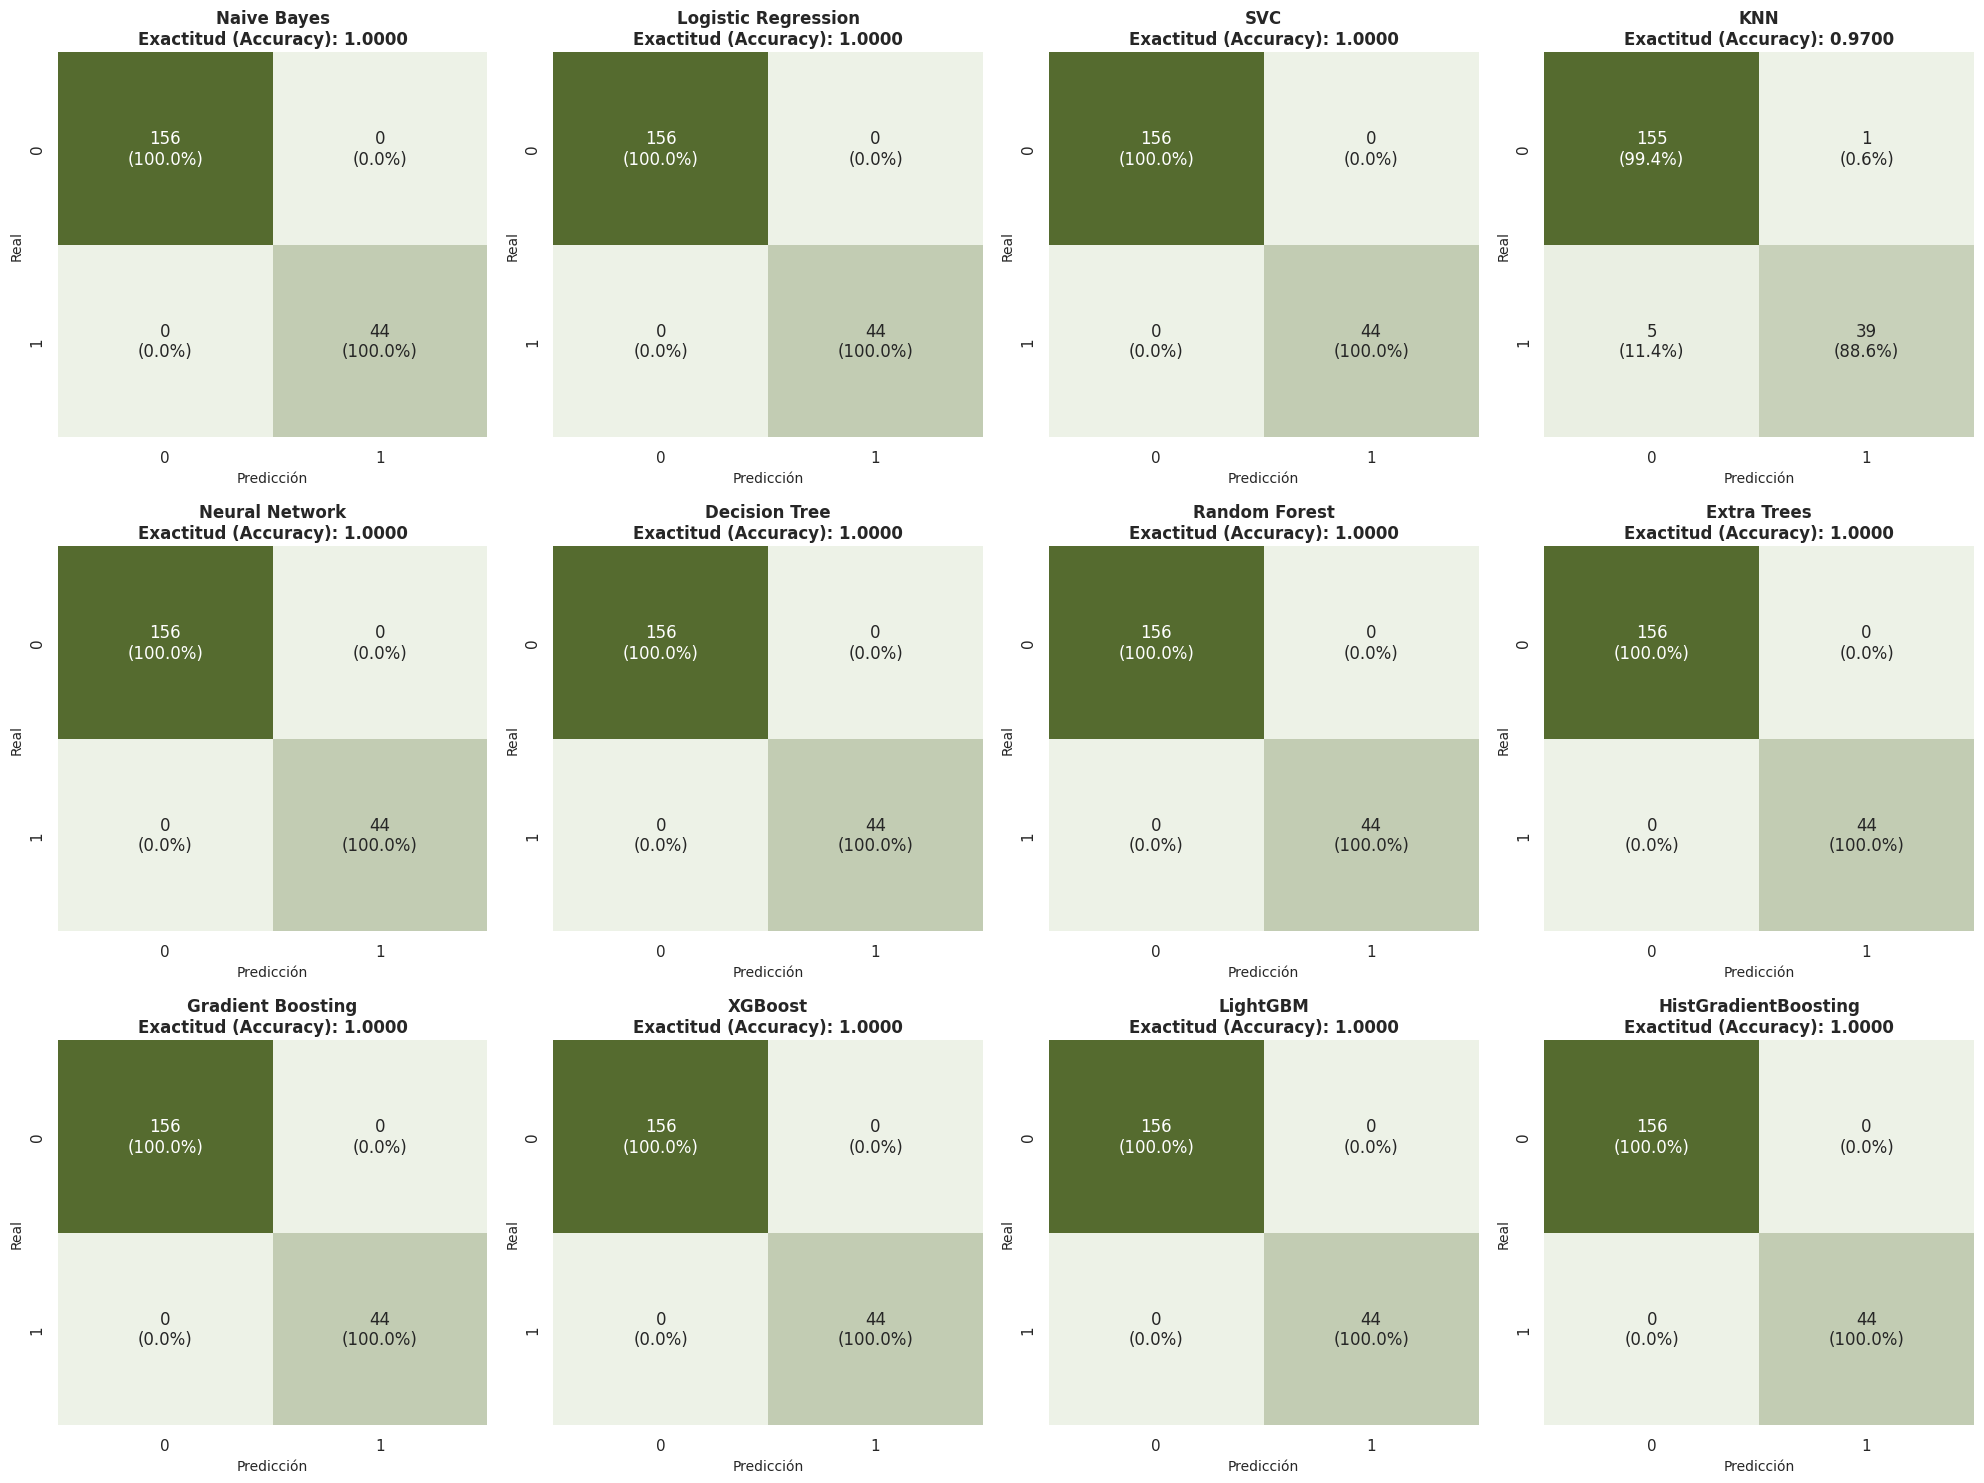

✅ Matrices de confusión guardadas en 'confusion_matrices.png'


In [27]:
def plot_confusion_matrices_with_percentages(best_models, X_test, y_test, le, cols=4):
    """
    Genera matrices de confusión con porcentajes para todos los modelos
    """
    n_models = len(best_models)
    rows = (n_models // cols) + (1 if n_models % cols > 0 else 0)

    fig, axes = plt.subplots(rows, cols, figsize=(20, 5*rows))
    axes = axes.flatten()

    for idx, (name, model) in enumerate(best_models.items()):
        y_pred = model.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        # Calcular porcentajes
        cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

        # Crear etiquetas (labels) con valores y porcentajes
        labels = []
        for i in range(len(cm)):
            row_labels = []
            for j in range(len(cm[0])):
                row_labels.append(f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)")
            labels.append(row_labels)

        # Graficar
        ax = axes[idx]
        sns.heatmap(
            cm, annot=labels, fmt='',
            cmap=sns.light_palette("#556B2F", as_cmap=True),
            ax=ax, cbar=False
        )
        ax.set_title(f"{name}\nExactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Predicción', fontsize=10)
        ax.set_ylabel('Real', fontsize=10)

    # Eliminar ejes vacíos
    for idx in range(n_models, len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Matrices de confusión guardadas en 'confusion_matrices.png'")

print("\n" + "="*70)
print("📈 GENERANDO MATRICES DE CONFUSIÓN CON %")
print("="*70)
plot_confusion_matrices_with_percentages(BEST_MODELS, X_test, y_test, le, cols=4)


### Reporte de Clasificación

In [28]:
from sklearn.metrics import classification_report


print("\n" + "="*70)
print("📋 REPORTES DE CLASIFICACIÓN + ESPECIFICIDAD")
print("="*70)

target_names_str = [str(c) for c in le.classes_] # ← Agregado aquí

for name, model in BEST_MODELS.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n🔹 {name}")
    print("-" * 30)
    print(classification_report(y_test, y_pred, target_names=target_names_str, digits=4)) # ← Usando la lista de strings

    # Cálculo de Especificidad para cada clase (One-vs-Rest)
    for i, class_label in enumerate(le.classes_):
        tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
        fp = np.sum(cm[:, i]) - cm[i, i]

        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        print(f"Especificidad ({class_label}):".ljust(25) + f"{specificity:.4f}")

    print(f"{'='*70}")


📋 REPORTES DE CLASIFICACIÓN + ESPECIFICIDAD

🔹 Naive Bayes
------------------------------
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       156
           1     1.0000    1.0000    1.0000        44

    accuracy                         1.0000       200
   macro avg     1.0000    1.0000    1.0000       200
weighted avg     1.0000    1.0000    1.0000       200

Especificidad (0):       1.0000
Especificidad (1):       1.0000

🔹 Logistic Regression
------------------------------
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       156
           1     1.0000    1.0000    1.0000        44

    accuracy                         1.0000       200
   macro avg     1.0000    1.0000    1.0000       200
weighted avg     1.0000    1.0000    1.0000       200

Especificidad (0):       1.0000
Especificidad (1):       1.0000

🔹 SVC
------------------------------
              precision    recall  

### Curva ROC


🎯 GENERANDO CURVAS ROC


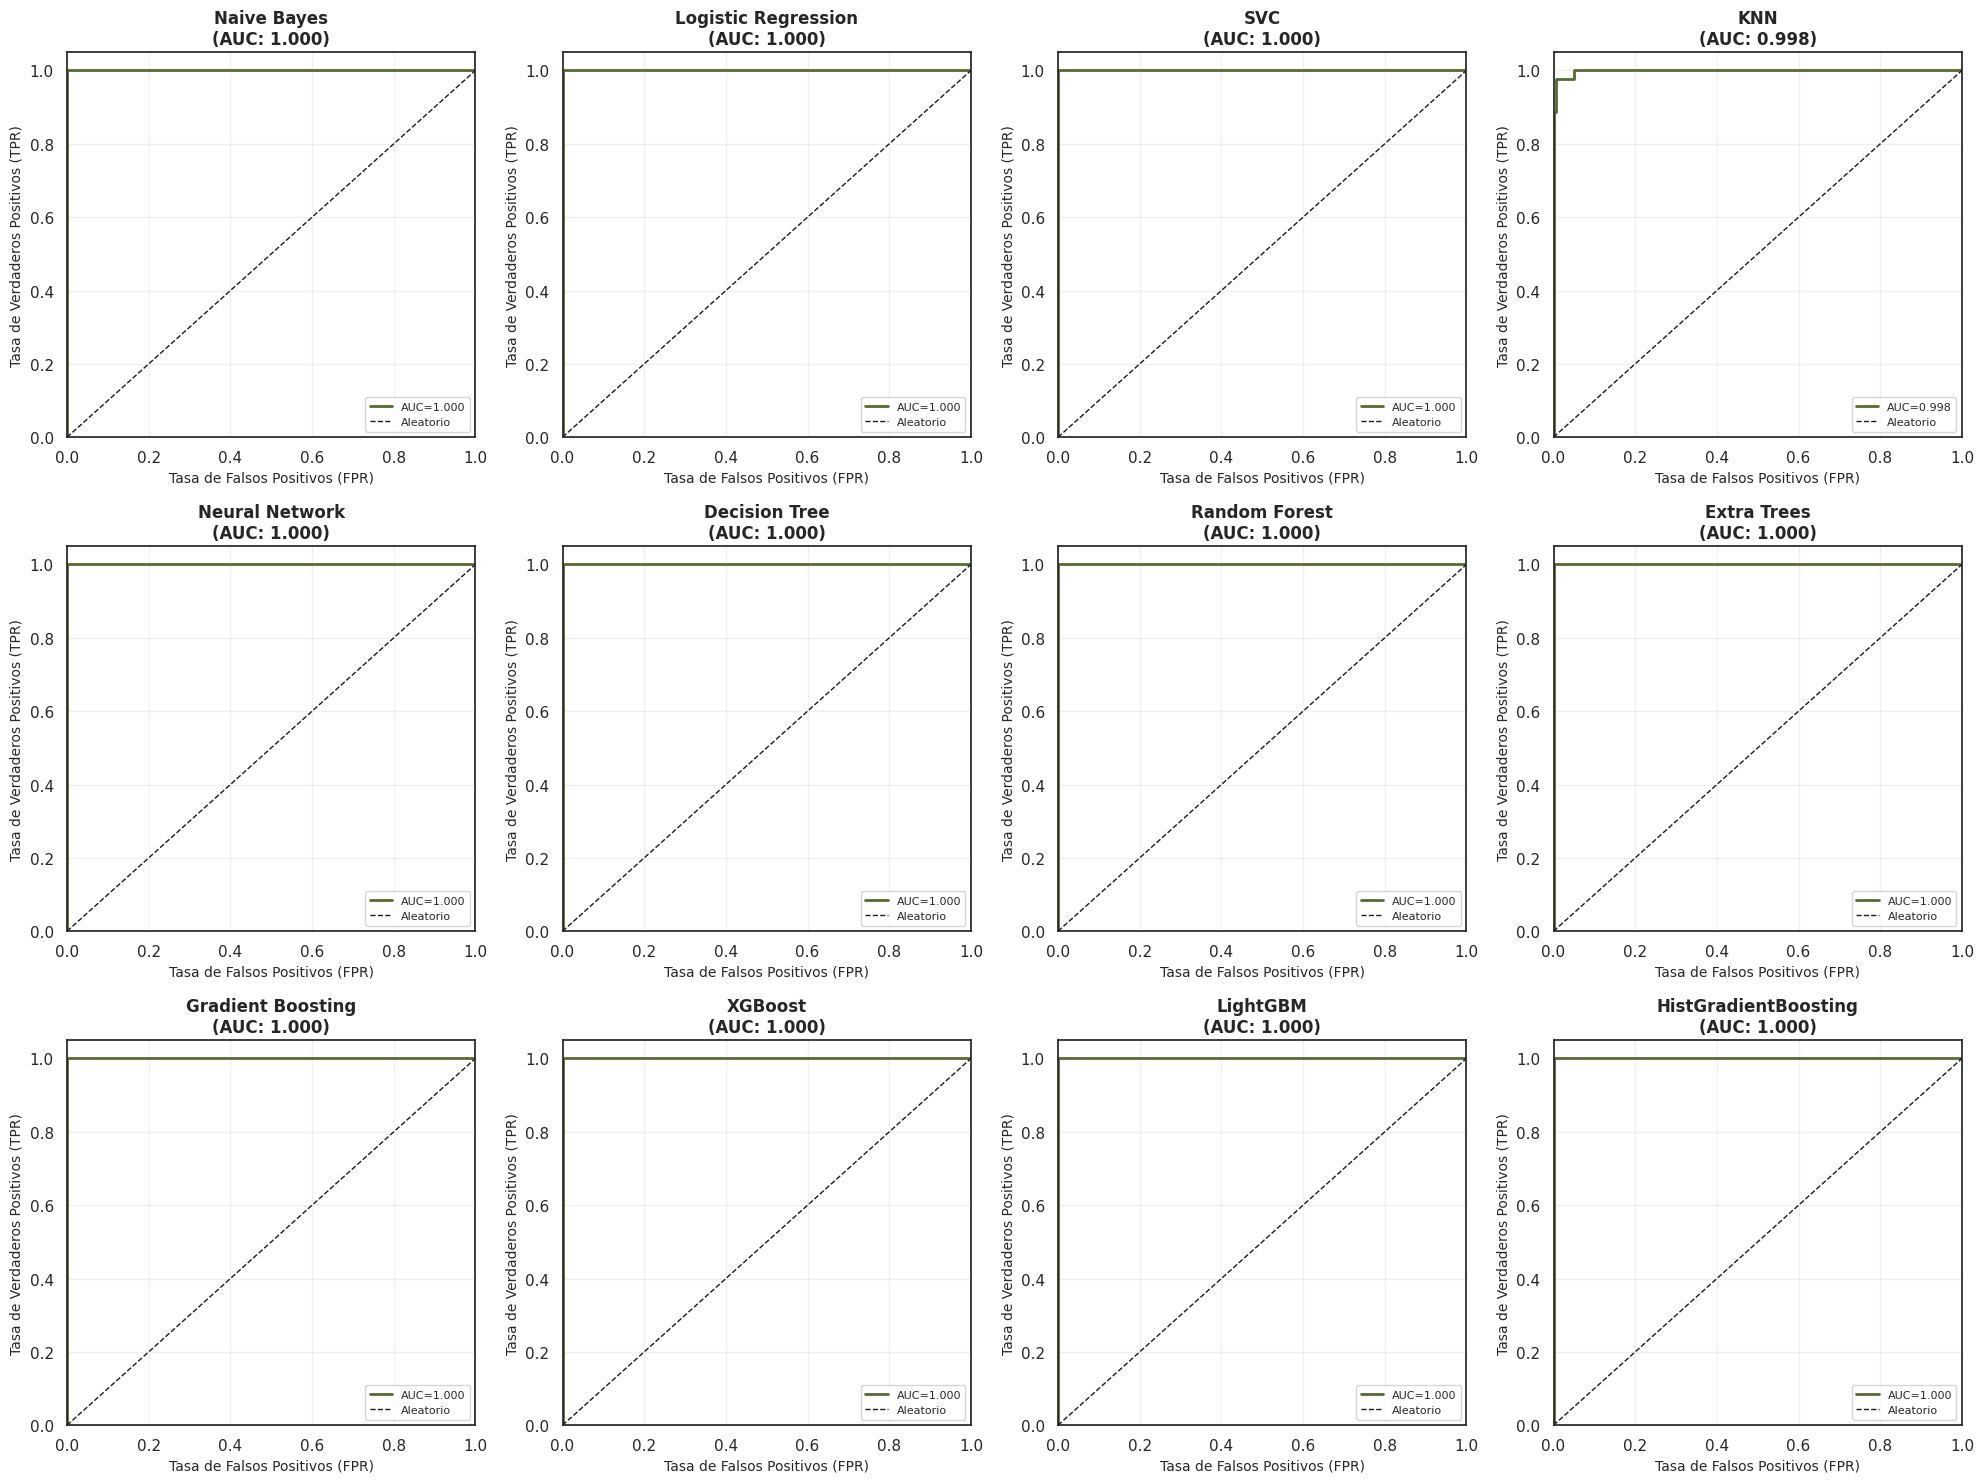

✅ Curvas ROC guardadas en 'roc_curves.png'


In [34]:
from sklearn.metrics import auc, roc_curve

def plot_roc_curves(best_models, X_test, y_test, n_classes, le, cols=4):
    """
    Genera curvas ROC
    """
    n_models = len(best_models)
    rows = (n_models // cols) + (1 if n_models % cols > 0 else 0)

    fig, axes = plt.subplots(rows, cols, figsize=(20, 5*rows))
    axes = axes.flatten()

    for idx, (name, model) in enumerate(best_models.items()):
        ax = axes[idx]

        # Obtener probabilidades
        try:
            y_proba = model.predict_proba(X_test)
        except Exception as e:
            print(f"⚠️ {name}: no se pudo obtener probabilidades ({e}), omitiendo curva ROC")
            continue

        # ROC binaria (clase positiva = 1)
        fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color='#556B2F', lw=2, label=f'AUC={roc_auc:.3f}')

        # Diagonal
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatorio')

        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
        ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=10)
        ax.set_title(f"{name}\n(AUC: {roc_auc:.3f})", fontsize=12, fontweight='bold')
        ax.legend(loc="lower right", fontsize=8)
        ax.grid(True, alpha=0.3)

    # Eliminar ejes vacíos
    for idx in range(n_models, len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Curvas ROC guardadas en 'roc_curves.png'")

print("\n" + "="*70)
print("🎯 GENERANDO CURVAS ROC")
print("="*70)
plot_roc_curves(BEST_MODELS, X_test, y_test, n_classes=2, le=le, cols=4)


In [35]:
from sklearn.model_selection import cross_val_predict

print("\n" + "="*70)
print("⚙️ ANÁLISIS DE OPTIMIZACIÓN DE UMBRALES (THRESHOLDS)")
print("="*70)

best_model_name = tuning_df.sort_values('CV AUC', ascending=False).iloc[0]['Model']
best_model_obj = BEST_MODELS[best_model_name]
print(f"\nOptimizando umbral para: {best_model_name}\n")

# 1) Elegir el umbral usando SOLO train (probabilidades fuera de pliegue)
proba_cv = cross_val_predict(clone(best_model_obj), X_train, y_train,
                             cv=CV, method='predict_proba')[:, 1]

threshold_results = []
for th in np.arange(0.1, 0.9, 0.05):
    pred_cv = (proba_cv > th).astype(int)
    threshold_results.append({
        'Umbral': round(th, 2),
        'F1-Score': round(f1_score(y_train, pred_cv), 4),
        'Precision': round(precision_score(y_train, pred_cv, zero_division=0), 4),
        'Recall': round(recall_score(y_train, pred_cv, zero_division=0), 4)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

best_th = threshold_df.loc[threshold_df['F1-Score'].idxmax(), 'Umbral']
print(f"\n✅ Umbral elegido con train (máximo F1): {best_th}")

# 2) Reportar en TEST una sola vez, con ese umbral
proba_test = best_model_obj.predict_proba(X_test)[:, 1]
pred_test = (proba_test > best_th).astype(int)
print(f"\n=== RESULTADO EN TEST con umbral {best_th} ===")
print(f"F1={f1_score(y_test, pred_test):.4f} | "
      f"Precisión={precision_score(y_test, pred_test, zero_division=0):.4f} | "
      f"Recall={recall_score(y_test, pred_test):.4f}")


⚙️ ANÁLISIS DE OPTIMIZACIÓN DE UMBRALES (THRESHOLDS)

Optimizando umbral para: Naive Bayes



,Umbral,F1-Score,Precision,Recall
0,0.10,1.0,1.0,1.0
1,0.15,1.0,1.0,1.0
2,0.20,1.0,1.0,1.0
3,0.25,1.0,1.0,1.0
4,0.30,1.0,1.0,1.0
5,0.35,1.0,1.0,1.0
6,0.40,1.0,1.0,1.0
7,0.45,1.0,1.0,1.0
8,0.50,1.0,1.0,1.0
9,0.55,1.0,1.0,1.0



✅ Umbral elegido con train (máximo F1): 0.1

=== RESULTADO EN TEST con umbral 0.1 ===
F1=1.0000 | Precisión=1.0000 | Recall=1.0000


### Comparación Visual 


GENERANDO COMPARATIVAS VISUALES


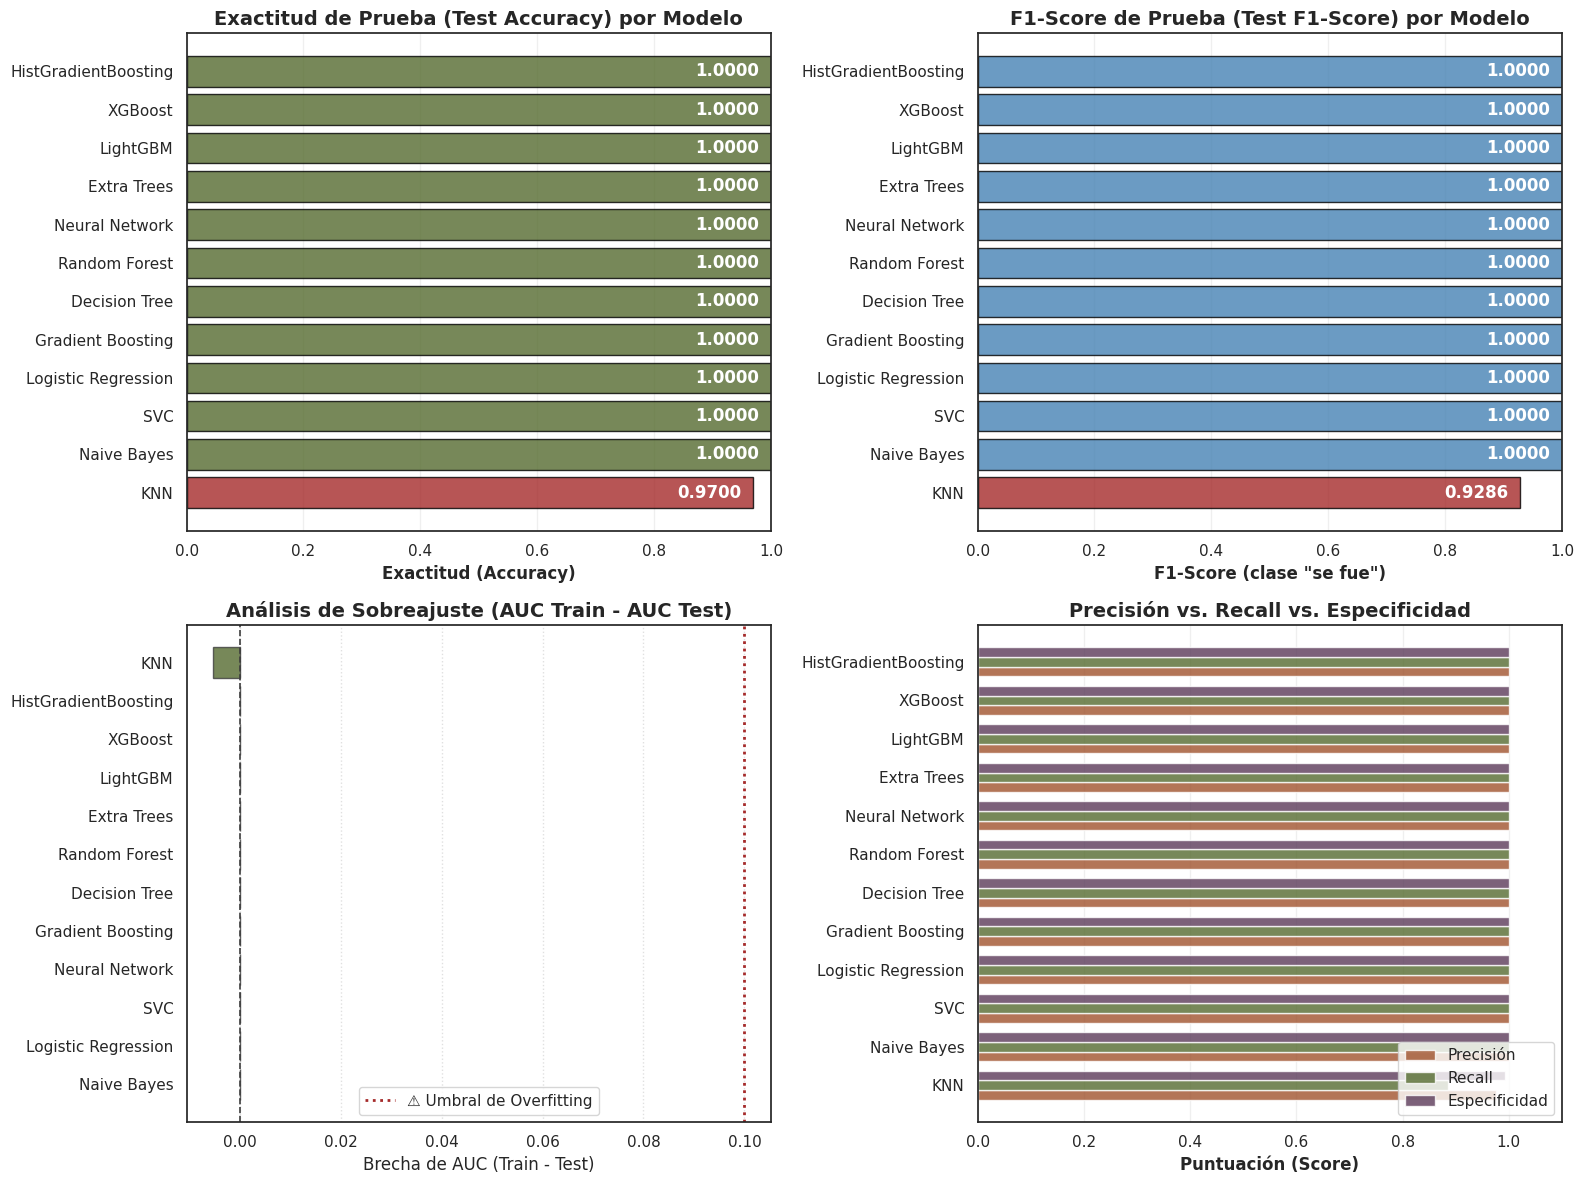

In [36]:
print("\n" + "="*70)
print("GENERANDO COMPARATIVAS VISUALES")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Comparación de exactitud (Accuracy)
ax1 = axes[0, 0]
tuning_df_sorted = tuning_df.sort_values('AUC Test', ascending=True)
# Si es mayor al promedio: #556B2F (Verde oliva), si es menor: #A52A2A (Marrón rojizo)
colors_acc = ["#556B2F" if x > tuning_df['Test Acc'].mean() else "#A52A2A"
              for x in tuning_df_sorted['Test Acc']]
ax1.barh(tuning_df_sorted['Model'], tuning_df_sorted['Test Acc'], color=colors_acc, edgecolor='black', alpha=0.8)
ax1.set_xlabel('Exactitud (Accuracy)', fontsize=12, fontweight='bold')
ax1.set_title('Exactitud de Prueba (Test Accuracy) por Modelo', fontsize=14, fontweight='bold')
ax1.set_xlim([0, 1])
ax1.grid(axis='x', alpha=0.3)
for i, v in enumerate(tuning_df_sorted['Test Acc']):
    ax1.text(v - 0.02, i, f'{v:.4f}', va='center', ha='right', fontweight='bold', color='white')

# Comparación de F1-Score
ax2 = axes[0, 1]
tuning_df_sorted_f1 = tuning_df.sort_values('Test F1', ascending=True)
# Si es mayor al promedio: #4682B4 (Azul acero), si es menor: #A52A2A (Marrón rojizo)
colors_f1 = ["#4682B4" if x > tuning_df['Test F1'].mean() else "#A52A2A"
             for x in tuning_df_sorted_f1['Test F1']]
ax2.barh(tuning_df_sorted_f1['Model'], tuning_df_sorted_f1['Test F1'], color=colors_f1, edgecolor='black', alpha=0.8)
ax2.set_xlabel('F1-Score (clase "se fue")', fontsize=12, fontweight='bold')
ax2.set_title('F1-Score de Prueba (Test F1-Score) por Modelo', fontsize=14, fontweight='bold')
ax2.set_xlim([0, 1])
ax2.grid(axis='x', alpha=0.3)
for i, v in enumerate(tuning_df_sorted_f1['Test F1']):
    ax2.text(v - 0.02, i, f'{v:.4f}', va='center', ha='right', fontweight='bold', color='white')

# Análisis de sobreajuste (Gap/Brecha)
ax3 = axes[1, 0]
tuning_df_sorted_gap = tuning_df.sort_values('AUC Gap', ascending=False)
colors_gap = ["#556B2F" if x <= 0.1 else "#A52A2A" for x in tuning_df_sorted_gap['AUC Gap']]
ax3.barh(tuning_df_sorted_gap['Model'], tuning_df_sorted_gap['AUC Gap'],
         color=colors_gap, edgecolor='#3D3D3D', alpha=0.8)
ax3.set_xlabel('Brecha de AUC (Train - Test)', fontsize=12)
ax3.set_title('Análisis de Sobreajuste (AUC Train - AUC Test)', fontsize=14, fontweight='bold')
ax3.axvline(0, color='#3D3D3D', lw=1.2, linestyle='--')
ax3.axvline(0.1, color='#A52A2A', linestyle=':', lw=2, label='⚠️ Umbral de Overfitting')
ax3.grid(axis='x', linestyle=':', alpha=0.6)
ax3.legend()

# Precisión vs. Exhaustividad (Recall) vs. Especificidad
ax4 = axes[1, 1]
tuning_df_sorted = tuning_df.sort_values('AUC Test', ascending=True)
x_pos = np.arange(len(tuning_df_sorted))
width = 0.25

# Colores directos: Siena (#A0522D), Verde oliva (#556B2F) y Púrpura oscuro (#5B3A59)
ax4.barh(x_pos - width, tuning_df_sorted['Precision'], width, label='Precisión', color="#A0522D", alpha=0.8)
ax4.barh(x_pos, tuning_df_sorted['Recall'], width, label='Recall', color="#556B2F", alpha=0.8)
ax4.barh(x_pos + width, tuning_df_sorted['Specificity'], width, label='Especificidad', color="#5B3A59", alpha=0.8)

ax4.set_yticks(x_pos)
ax4.set_yticklabels(tuning_df_sorted['Model'])
ax4.set_xlabel('Puntuación (Score)', fontsize=12, fontweight='bold')
ax4.set_title('Precisión vs. Recall vs. Especificidad', fontsize=14, fontweight='bold')
ax4.legend(loc='lower right', frameon=True)
ax4.grid(axis='x', alpha=0.3)
ax4.set_xlim([0, 1.1])

plt.tight_layout()
plt.savefig('model_comparisons.png', dpi=300, bbox_inches='tight')
plt.show()

## Reporte Final

In [37]:
from sklearn.inspection import permutation_importance

for name, model in BEST_MODELS.items():
    perm_importance = permutation_importance(model, X_test, y_test, n_repeats=10, scoring='roc_auc', random_state=SEED)
    print(f"{name} - Importancia de Características (Feature Importance):")
    for feat, imp in zip(X_test.columns, perm_importance.importances_mean):
        print(f"  {feat}: {imp:.4f}")

Naive Bayes - Importancia de Características (Feature Importance):
  credit_score: 0.0000
  geography: 0.0000
  gender: 0.0000
  age: 0.0000
  balance: 0.0000
  num_of_products: 0.0000
  is_active_member: 0.0000
  estimated_salary: 0.0000
  complain: 0.5259
  point_earned: 0.0000
Logistic Regression - Importancia de Características (Feature Importance):
  credit_score: 0.0000
  geography: 0.0000
  gender: 0.0000
  age: 0.0000
  balance: 0.0000
  num_of_products: 0.0000
  is_active_member: 0.0000
  estimated_salary: 0.0000
  complain: 0.3247
  point_earned: 0.0000
SVC - Importancia de Características (Feature Importance):
  credit_score: 0.0000
  geography: 0.0000
  gender: 0.0000
  age: 0.0000
  balance: 0.0000
  num_of_products: 0.0000
  is_active_member: 0.0000
  estimated_salary: 0.0000
  complain: 0.3144
  point_earned: 0.0000
KNN - Importancia de Características (Feature Importance):
  credit_score: -0.0003
  geography: 0.0032
  gender: 0.0007
  age: 0.0074
  balance: 0.0006
  num

In [38]:
import joblib

print("\n" + "="*70)
print("REPORTE FINAL")
print("="*70)

best_model_name = tuning_df.sort_values('CV AUC', ascending=False).iloc[0]['Model']
best_model_obj = BEST_MODELS[best_model_name]
y_pred_best = best_model_obj.predict(X_test)

best_row = tuning_df[tuning_df['Model'] == best_model_name].iloc[0]

print(f"\n🏆 MEJOR MODELO (según CV AUC): {best_model_name}")
print(f"   CV AUC: {best_row['CV AUC']:.4f} | AUC Test: {best_row['AUC Test']:.4f}")
print(f"   Exactitud (Accuracy): {best_row['Test Acc']:.4f}")
print(f"   F1-Score: {best_row['Test F1']:.4f}")
print(f"   Precisión: {best_row['Precision']:.4f}")
print(f"   Exhaustividad (Recall): {best_row['Recall']:.4f}")
print(f"   Brecha de Sobreajuste (AUC Gap): {best_row['AUC Gap']:.4f}")

print(f"\n📌 TOP 3 MODELOS (por CV AUC):")
top3 = tuning_df.sort_values('CV AUC', ascending=False).head(3)
for i, (_, row) in enumerate(top3.iterrows(), 1):
    print(f"   {i}. {row['Model']:<25} → CV AUC={row['CV AUC']:.4f} | AUC Test={row['AUC Test']:.4f} | F1={row['Test F1']:.4f}")

print("\n" + "="*70)
print("✅ ANÁLISIS COMPLETADO")
print("="*70)
print("📁 Archivos generados:")
print("   • confusion_matrices.png")
print("   • roc_curves.png")
print("   • model_comparisons.png")

best_model_name = tuning_df.sort_values('CV AUC', ascending=False).iloc[0]['Model']
best_row = tuning_df[tuning_df['Model'] == best_model_name].iloc[0]
best_model_obj = BEST_MODELS[best_model_name]

joblib.dump(best_model_obj, f'best_model_{best_model_name.replace(" ", "_")}.pkl')
print(f"   • best_model_{best_model_name.replace(' ', '_')}.pkl")


REPORTE FINAL

🏆 MEJOR MODELO (según CV AUC): Naive Bayes
   CV AUC: 1.0000 | AUC Test: 1.0000
   Exactitud (Accuracy): 1.0000
   F1-Score: 1.0000
   Precisión: 1.0000
   Exhaustividad (Recall): 1.0000
   Brecha de Sobreajuste (AUC Gap): 0.0000

📌 TOP 3 MODELOS (por CV AUC):
   1. Naive Bayes               → CV AUC=1.0000 | AUC Test=1.0000 | F1=1.0000
   2. Logistic Regression       → CV AUC=1.0000 | AUC Test=1.0000 | F1=1.0000
   3. SVC                       → CV AUC=1.0000 | AUC Test=1.0000 | F1=1.0000

✅ ANÁLISIS COMPLETADO
📁 Archivos generados:
   • confusion_matrices.png
   • roc_curves.png
   • model_comparisons.png
   • best_model_Naive_Bayes.pkl
